# Did the AI video editor make the requested revision?
A 12-second cut and its 10-second revision share an opening. Scrub only the opening and both look right. Check the two frames on either side of the revised join and the difference becomes visible.

**Run all cells** in Colab or Jupyter with Python, Pillow, FFmpeg and ffprobe. The notebook fetches three small public MP4s. A recorded first preview serves as a negative control. A later Valmera export serves as a second example. You can also test an export from another editor using the same source and brief.

1. [Download the silent 25-second source](https://valmera.io/examples/trim-and-reframe/original-source.mp4). Its onscreen clock gives the source time in seconds and frames.
2. Ask the editor to keep source seconds 3–7, 12–16 and 19–23 in that order, center-crop to square and use hard cuts at 30 fps. Leave the original speed and colors in place.
3. Ask for one revision. Shorten the middle selection to 12–14 and keep everything else. Export the result.
4. To check your MP4, set `custom_export` in the next cell to its runtime file path. A local Jupyter kernel can read a local file. In Colab, adding your file to the runtime transfers it to Google's servers. The built-in examples need no upload.

Published by Valmera. This checks timing and picture selection on a prescribed cut. It leaves shot choice, dialogue, audio, captions and artistic judgment for a separate trial. [See the recorded MCP run and the exact editing requests.](https://github.com/ABO3SKRALMASAOODI/valmera-mcp/blob/main/docs/MCP-RECORDED-EDIT.md)

In [1]:
from hashlib import sha256
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen
from io import BytesIO
from statistics import mean
import json
import shutil
import subprocess
from PIL import Image, ImageChops, ImageDraw, ImageStat
from IPython.display import display

custom_export = None  # Example: "/content/my-revised-export.mp4"
for tool in ["ffmpeg", "ffprobe"]:
    if not shutil.which(tool):
        raise RuntimeError(f"Install {tool}, then rerun this notebook.")

work = TemporaryDirectory()
base = "https://raw.githubusercontent.com/ABO3SKRALMASAOODI/valmera-mcp/102cdd4784c0058e9866446f8a25a0bade227e39/docs/evaluation/recorded-run-20261107/"
hashes = {
    "original-source.mp4": "24dc72de92df8e0d212fa9ca068d3ffdacab55f74b91c32249be96e9e74defdf",
    "first-preview.mp4": "1e06d2d4eb1b0db11b9be84867400c669b72a4bb8f1bdcb5cfb69d3521af7080",
    "revised-final.mp4": "9b7f97b8e75c80b49c8e2c61f2bace1c279cc26599d65b28b5d4d394bcdc592e",
}
files = {}
for name, digest in hashes.items():
    with urlopen(base + name, timeout=30) as response:
        data = response.read()
    if sha256(data).hexdigest() != digest:
        raise ValueError(f"Reference download failed its checksum: {name}")
    files[name] = Path(work.name) / name
    files[name].write_bytes(data)
print("Verified the source, first preview and revised export.")

Verified the source, first preview and revised export.


## Map each output frame back to the source
At output frame 179, both versions should show source frame 419 (13 seconds and 29 frames). At output frame 180, the revision jumps to source frame 570 (19 seconds). The first cut stays on source frame 420. Start times below are inclusive and end times exclusive.

In [2]:
fps = 30
def source_schedule(ranges):
    return [frame for start, end in ranges for frame in range(start * fps, end * fps)]

first = source_schedule([(3, 7), (12, 16), (19, 23)])
revision = source_schedule([(3, 7), (12, 14), (19, 23)])

def video_info(path):
    raw = subprocess.check_output(["ffprobe", "-v", "error", "-select_streams", "v:0",
        "-show_entries", "stream=width,height,duration,avg_frame_rate", "-of", "json", str(path)])
    return json.loads(raw)["streams"][0]

def decode(path, count, crop=False):
    # Sample a fixed-size grayscale thumbnail at each output clock tick.
    filters = ["fps=30"]
    if crop:
        filters.append("crop=ih:ih:(iw-ih)/2:0")
    filters += ["scale=96:96:flags=area", "format=gray"]
    raw = subprocess.check_output(["ffmpeg", "-v", "error", "-i", str(path),
        "-vf", ",".join(filters), "-frames:v", str(count), "-f", "rawvideo", "pipe:1"])
    stride = 96 * 96
    return [Image.frombytes("L", (96, 96), raw[i:i+stride]) for i in range(0, len(raw), stride)]

source = decode(files["original-source.mp4"], 23 * fps, crop=True)
cases = {"First preview": files["first-preview.mp4"], "Valmera revision": files["revised-final.mp4"]}
if custom_export:
    cases["Your export"] = Path(custom_export).expanduser().resolve(strict=True)

samples = {}
def distance(a, b):
    return ImageStat.Stat(ImageChops.difference(a, b)).mean[0]

for name, path in cases.items():
    info = video_info(path)
    if info["width"] != info["height"]:
        print(f"{name}: expected square, got {info['width']} × {info['height']}. Check framing before comparing pictures.")
        continue
    frames = decode(path, len(revision))
    if len(frames) < len(revision):
        print(f"{name}: contains only {len(frames)} of the required {len(revision)} sampling ticks. Check for a missing shot.")
        continue
    samples[name] = frames
    print(f"{name}: {info['width']} × {info['height']}, {info.get('duration', 'unknown')} seconds, average fps {info['avg_frame_rate']}.")

First preview: 720 × 720, 12.000000 seconds, average fps 30/1.


Valmera revision: 1080 × 1080, 15.000000 seconds, average fps 30/1.


## Compare the disputed part of the cut
Output seconds 0–6 are identical in the two instructions. The table below uses only seconds 6–10. For each of those 120 output samples, compare its brightness to the expected source under each instruction. A lower mean difference means closer pictures (0–255 scale). The code also counts which reference was closer on each frame. Similar pictures can tie.

Both scores can be high for unrelated footage, a different crop, a stylized grade or a large overlay. There is no automatic pass threshold. Read the source clocks in the pictures before interpreting a small difference. Sampling at 30 Hz places other frame rates on a common clock and cannot establish original frame accuracy for variable-rate media.

In [3]:
print(f"{'Export':18} {'First cut':>10} {'Revision':>10} {'Closer frames (first / revised / equal)':>40}")
for name, frames in samples.items():
    a = [distance(frames[t], source[first[t]]) for t in range(180, 300)]
    b = [distance(frames[t], source[revision[t]]) for t in range(180, 300)]
    wins = (sum(x < y for x, y in zip(a,b)), sum(y < x for x, y in zip(a,b)), sum(x == y for x,y in zip(a,b)))
    print(f"{name:18} {mean(a):10.2f} {mean(b):10.2f} {str(wins):>40}")

Export              First cut   Revision  Closer frames (first / revised / equal)
First preview            0.03       4.08                              (120, 0, 0)
Valmera revision         7.40       3.45                              (0, 120, 0)


## Inspect the join at full color
Read each row across. The left column shows the last frame before the revised join. The next column shows the first frame after it. At eight seconds the first cut finally reaches the closing shot, while the revision should already be two seconds into it. Extra branding after ten seconds affects the file duration and is outside the picture comparison.

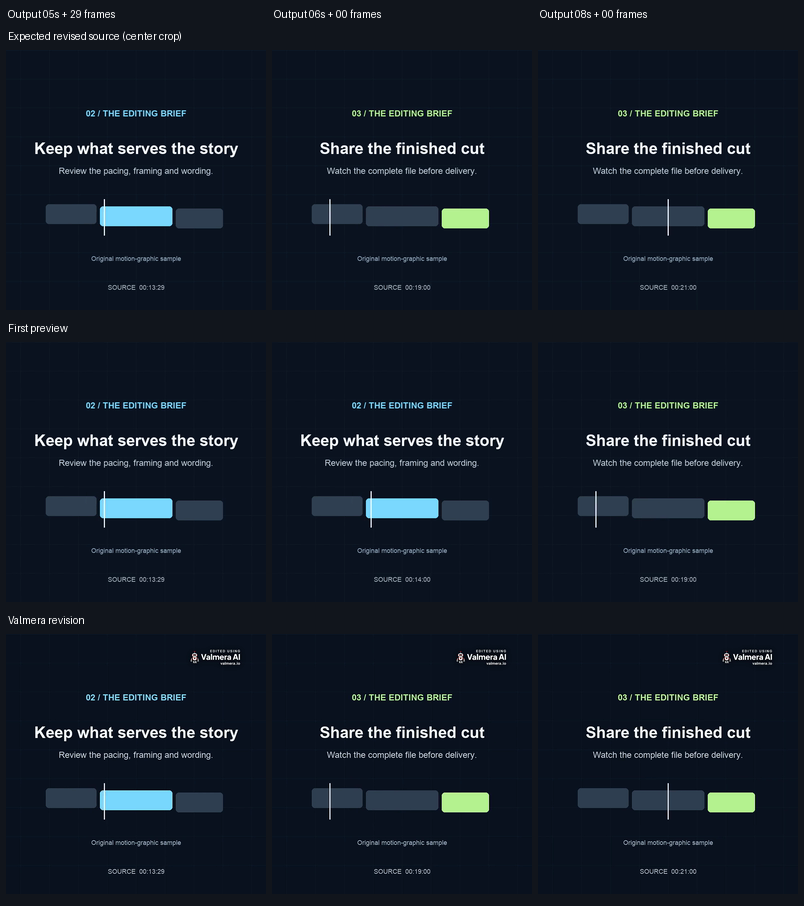

In [4]:
def color_frame(path, index, crop):
    filters = ["fps=30", f"select=eq(n\\,{index})"]
    if crop:
        filters.append("crop=ih:ih:(iw-ih)/2:0")
    filters.append("scale=260:260:flags=lanczos")
    image = subprocess.check_output(["ffmpeg", "-v", "error", "-i", str(path), "-vf", ",".join(filters),
        "-frames:v", "1", "-f", "image2pipe", "-c:v", "png", "pipe:1"])
    return Image.open(BytesIO(image)).convert("RGB")

ticks = (179, 180, 240)
rows = [("Expected revised source (center crop)", files["original-source.mp4"], True)]
rows += [(name, cases[name], False) for name in samples]
sheet = Image.new("RGB", (804, 30 + 292 * len(rows)), "#11151c")
draw = ImageDraw.Draw(sheet)
for j, label in enumerate(("Output 05s + 29 frames", "Output 06s + 00 frames", "Output 08s + 00 frames")):
    draw.text((8 + 266*j, 8), label, fill="white")
for row, (name, path, crop) in enumerate(rows):
    top = 30 + 292 * row
    draw.text((8, top), name, fill="white")
    for j, tick in enumerate(ticks):
        index = revision[tick] if crop else tick
        picture = color_frame(path, index, crop)
        sheet.paste(picture, (6 + 266*j, top + 20))
display(sheet)

The first preview should still show the middle shot at six seconds. The revised export should match the source clock at that join and retain the closing four seconds. Carry the output timestamp, source timestamp and a still into any revision request. If your file is shorter than ten seconds, check the missing selection first. If it is longer, play the tail before accepting delivery.

[Watch the synchronized local and hosted exports](https://valmera.io/mcp/claude-code#compare-video-editing-skills) or [compare AI video editors for existing footage](https://valmera.io/ai-video-editor).